In [1]:
import pandas as pd
import numpy as np
import glob
import os

from clustering_tools import *

# pd.set_option('display.max_columns', None)
pd.reset_option('display.max_columns')

In [2]:
cosmic_path = '../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'
cosmic = pd.read_csv(cosmic_path, sep = '\t').set_index('Type').T
cosmic_contexts = cosmic.rename(columns={col: col[0] + col[2] + col[-1] for col in cosmic.columns}).groupby(level=0, axis=1).sum()
cosmic_substitutions = cosmic.rename(columns={col: col[2:5] for col in cosmic.columns}).groupby(level=0, axis=1).sum()

breast_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a', 'SBS17b', 'SBS18', 'SBS37', 'SBS40a', 'SBS40b', 'SBS40c', 'SBS41']
ovary_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS13', 'SBS18', 'SBS26', 'SBS35', 'SBS39', 'SBS40', 'SBS41']

P = {}
for filepath in glob.glob(os.path.join('../data/funnell_tables/', '*_sbs_counts.csv')):
    key = os.path.basename(filepath).split('_')[0]  # e.g., 'SA501'
    P[key] = sample(key)

meta = sample(id='meta', filepath='../data/funnell_tables/meta.csv')

dmg_sig = pd.read_csv('../data/damuta/damage_signatures.csv', index_col=0).sort_index(axis=1)
misr_sig = pd.read_csv('../data/damuta/misrepair_signatures.csv', index_col=0).sort_index(axis=1)

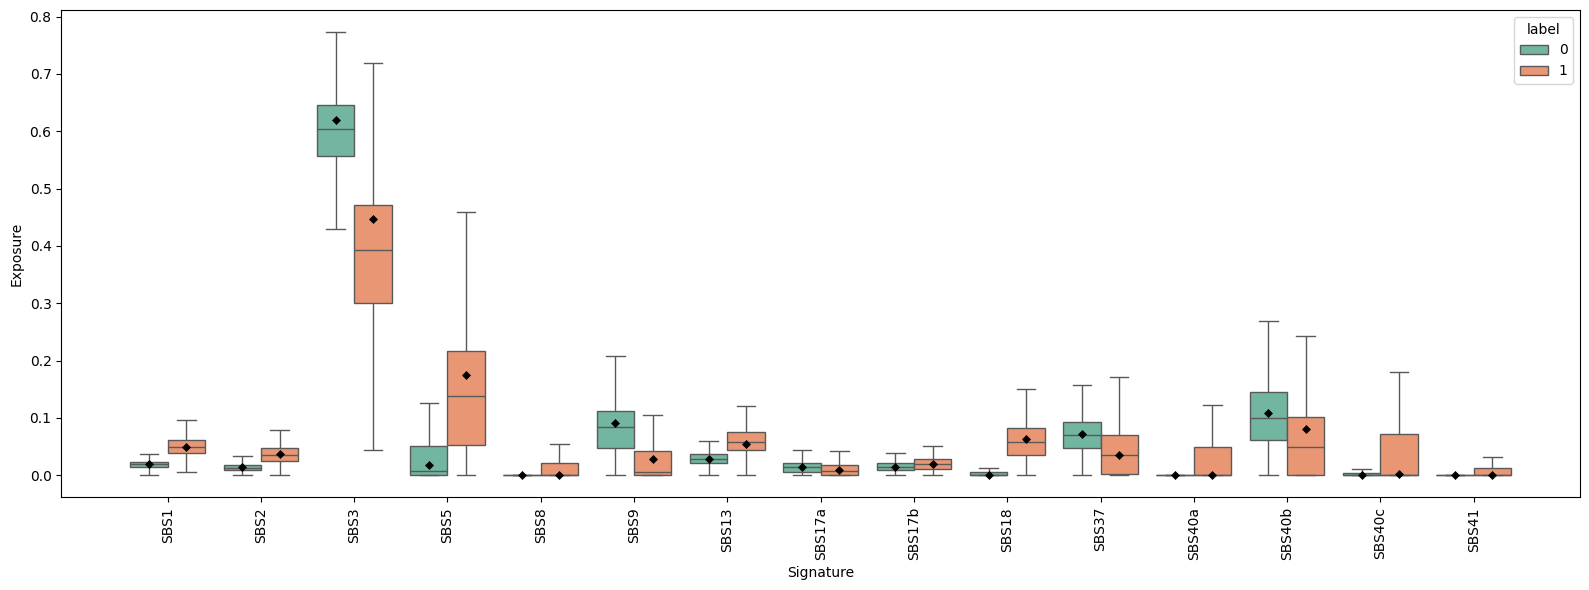

In [3]:
y = P['SA604']
y.umap().hdbscan().plot_deconv(signatures=cosmic.loc[breast_sigs])

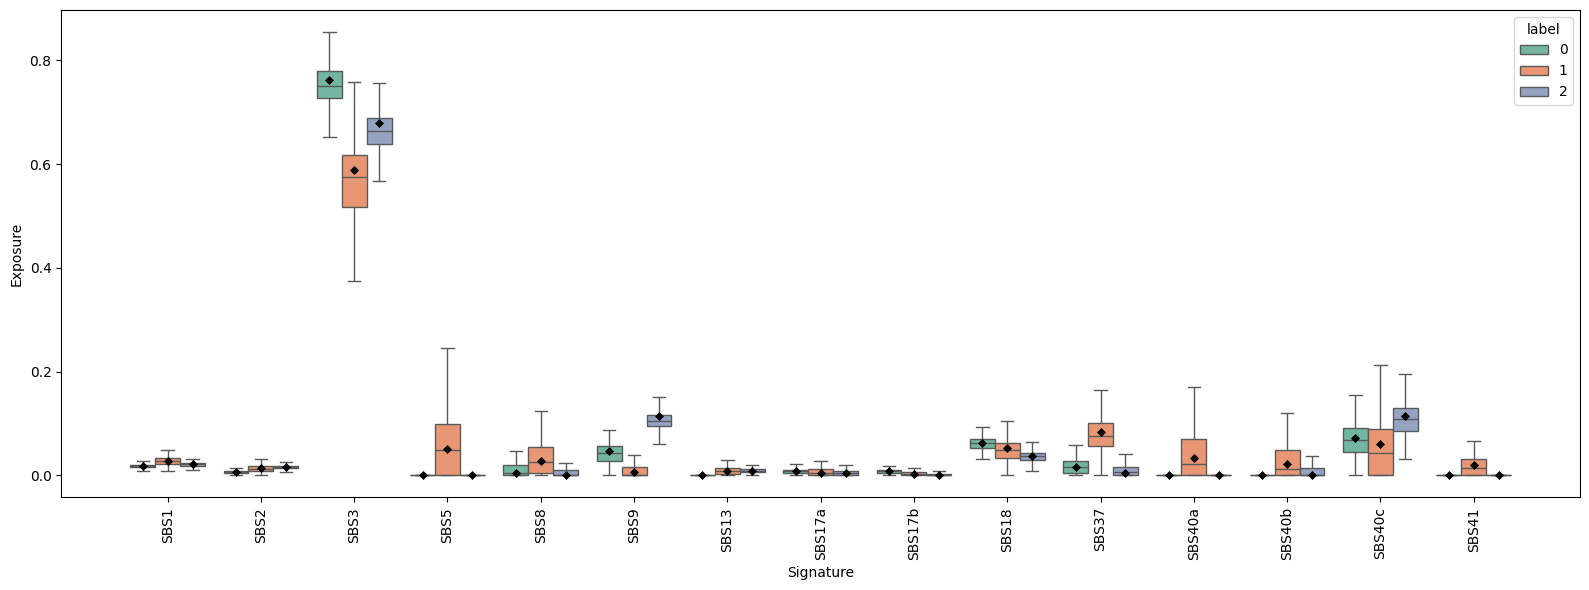

In [4]:
y = P['OV2295']
y.umap().hdbscan().plot_deconv(signatures=cosmic.loc[breast_sigs])

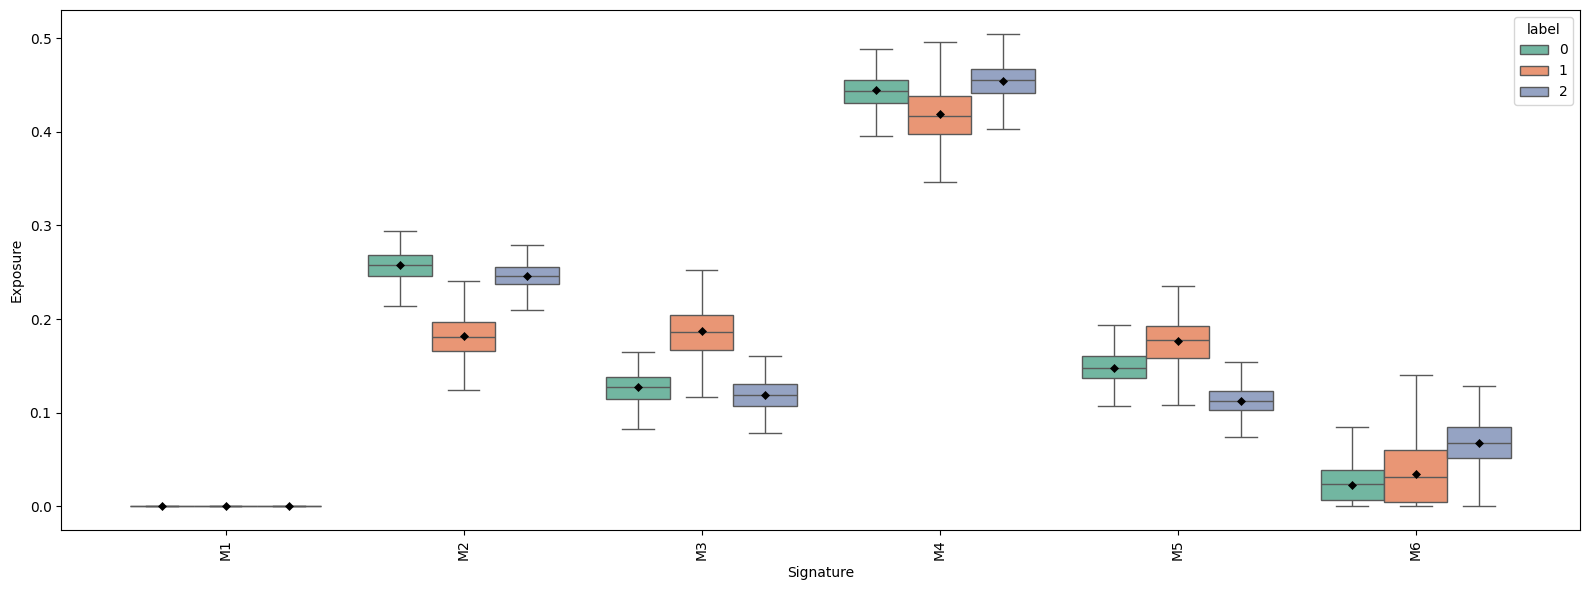

In [6]:
y.umap().hdbscan().plot_deconv(signatures=misr_sig)

In [3]:
y = P['SA604']
# y = P['OV2295']
# y = P['SA039']
# y = P['SA1142']


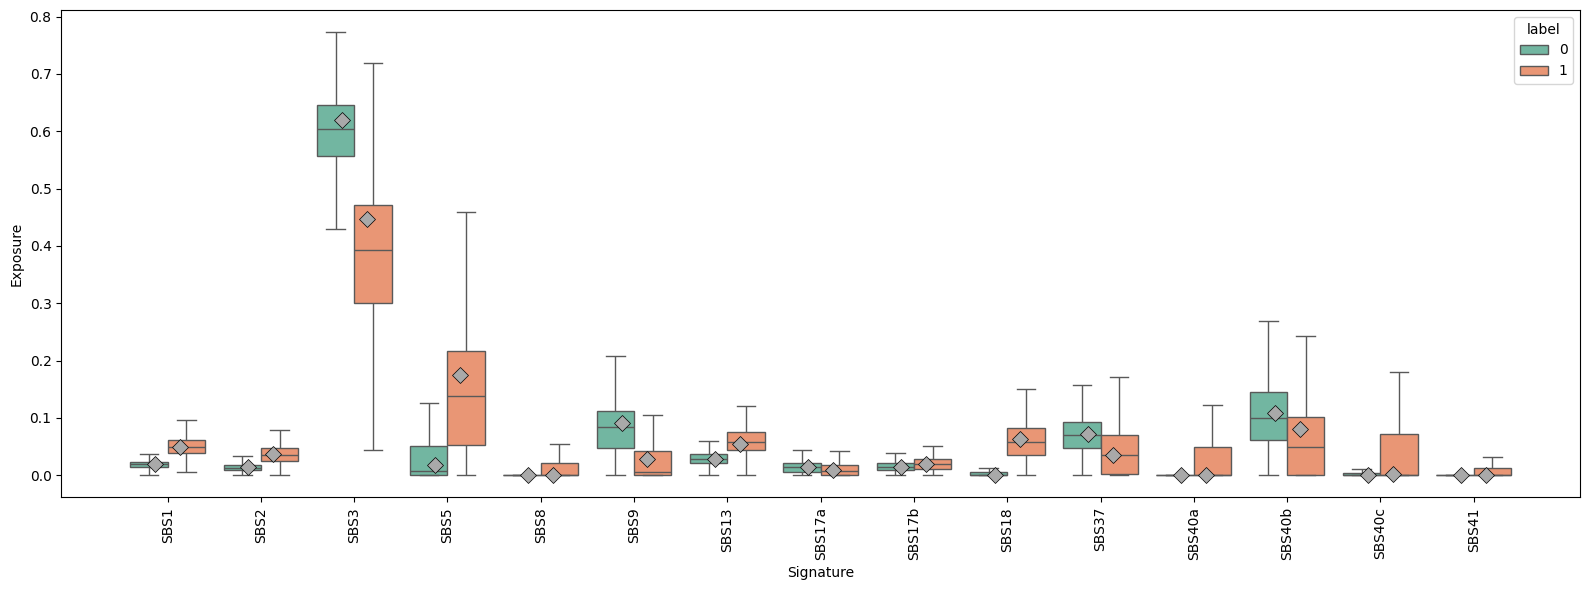

In [4]:
y.umap().hdbscan().plot_deconv(signatures=cosmic.loc[breast_sigs])

In [6]:
crosstable(y.umap(metric='hellinger').hdbscan().get_labels(),
           y.umap().hdbscan().get_labels())

Cluster B,0,1
Cluster A,,
-1,276,23
0,1096,34
1,28,635


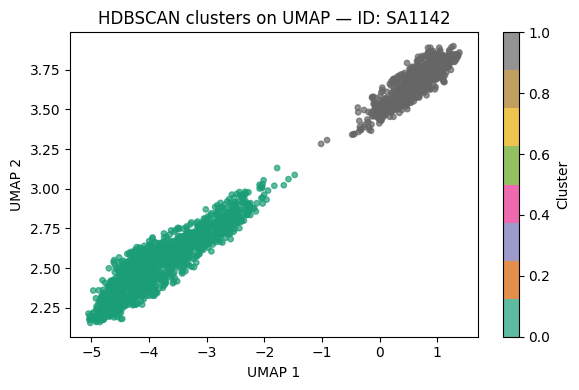

In [4]:
y.umap().hdbscan().plot_clustering()

In [21]:
cosmic.loc[breast_sigs]

Type,A[C>A]A,A[C>A]C,A[C>A]G,A[C>A]T,A[C>G]A,A[C>G]C,A[C>G]G,A[C>G]T,A[C>T]A,A[C>T]C,...,T[T>A]G,T[T>A]T,T[T>C]A,T[T>C]C,T[T>C]G,T[T>C]T,T[T>G]A,T[T>G]C,T[T>G]G,T[T>G]T
SBS1,8.760226e-04,0.002220,0.000180,0.001265,1.839055e-03,0.001188,1.167715e-04,0.001127,0.024718,6.154017e-03,...,2.773639e-05,0.002221,2.476139e-04,0.003397,4.121569e-04,0.004274,2.165026e-16,5.520354e-05,0.000578,2.200872e-16
SBS2,5.789892e-07,0.000146,0.000054,0.000098,2.226114e-16,0.000131,1.558278e-05,0.000091,0.000061,1.356732e-03,...,5.011497e-05,0.000204,2.186255e-16,0.000044,1.170380e-04,0.000036,1.637241e-05,7.122391e-05,0.000095,2.222453e-16
SBS3,2.091975e-02,0.016343,0.001808,0.012265,1.981342e-02,0.011589,2.613197e-04,0.017493,0.014282,1.228216e-02,...,6.762433e-03,0.013053,1.501379e-02,0.009164,6.984152e-03,0.013957,7.161182e-03,6.401230e-03,0.008113,1.054309e-02
SBS5,1.205205e-02,0.009337,0.001908,0.006636,1.014381e-02,0.005638,1.774054e-03,0.010140,0.032741,1.770486e-02,...,4.820615e-03,0.008774,1.775439e-02,0.009883,1.278117e-02,0.018550,5.148772e-03,6.677196e-03,0.006984,1.353626e-02
SBS8,4.431064e-02,0.047300,0.004767,0.047205,4.350682e-03,0.002919,2.951166e-04,0.005735,0.006843,2.790476e-03,...,1.298813e-02,0.038018,2.052515e-03,0.002688,2.235256e-16,0.004584,2.190754e-16,1.160874e-03,0.003111,9.991121e-04
SBS9,5.606393e-04,0.004047,0.000440,0.003063,4.862890e-03,0.001939,1.403288e-03,0.006438,0.008138,5.363004e-03,...,1.681330e-02,0.017052,1.381436e-02,0.013848,9.373161e-03,0.038518,6.482880e-02,8.777423e-03,0.010974,6.409665e-02
SBS13,1.816879e-03,0.000709,0.000271,0.000347,3.863364e-03,0.000935,2.706555e-04,0.003991,0.007168,2.182662e-16,...,1.880618e-04,0.000062,2.166804e-05,0.000025,9.983703e-05,0.000529,1.803957e-04,2.246143e-16,0.000037,1.883740e-05
SBS17a,2.072799e-03,0.000905,0.000049,0.000062,1.011366e-03,0.000561,1.563107e-04,0.000020,0.001222,1.686331e-03,...,1.836222e-03,0.001979,2.055355e-03,0.015527,2.357991e-03,0.020994,2.182924e-16,1.177218e-04,0.000923,4.578653e-03
SBS17b,6.077685e-04,0.000127,0.000060,0.000456,1.459445e-04,0.000043,2.289435e-16,0.000319,0.000571,6.921173e-05,...,2.233864e-16,0.001307,1.040625e-03,0.001114,1.212014e-03,0.000998,1.197783e-05,8.864484e-03,0.004788,1.217531e-01
SBS18,5.168832e-02,0.015617,0.002505,0.021469,1.736326e-03,0.002560,1.978997e-03,0.004093,0.009234,4.596190e-03,...,1.800220e-03,0.007114,1.774235e-03,0.006286,3.278612e-03,0.003377,6.860381e-04,2.136069e-03,0.001458,5.170353e-03


In [22]:
y.umap().hdbscan().deconv(signatures=cosmic.loc[breast_sigs])[0]

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a,SBS17b,SBS18,SBS37,SBS40a,SBS40b,SBS40c,SBS41
cell_id,,,,,,,,,,,,,,,
SA604X6XB01975-A96180A-R03-C08,0.011489,0.026344,0.612130,0.000000,0.00000,0.114001,0.018222,0.000000,0.014724,0.000000,0.112570,0.0,0.090519,0.000000,0.0
SA604X6XB01975-A96180A-R03-C12,0.002312,0.030588,0.428776,0.000000,0.00000,0.000000,0.047269,0.015384,0.011649,0.000000,0.119933,0.0,0.285629,0.058460,0.0
SA604X6XB01975-A96180A-R03-C14,0.009535,0.005181,0.496849,0.000000,0.00000,0.096603,0.048126,0.012006,0.019242,0.000000,0.082422,0.0,0.154875,0.075162,0.0
SA604X6XB01975-A96180A-R03-C17,0.023156,0.014922,0.506774,0.042790,0.00000,0.181042,0.023255,0.013968,0.005669,0.000000,0.031036,0.0,0.157389,0.000000,0.0
SA604X6XB01975-A96180A-R03-C20,0.026810,0.013371,0.440112,0.154201,0.00000,0.128890,0.027215,0.019127,0.007854,0.000000,0.108796,0.0,0.073623,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SA604X8XB02204-A96161A-R42-C49,0.037153,0.000593,0.540449,0.067933,0.00000,0.049964,0.028117,0.068075,0.023006,0.020156,0.101701,0.0,0.062853,0.000000,0.0
SA604X8XB02204-A96161A-R42-C63,0.015985,0.008958,0.500686,0.229446,0.00000,0.019123,0.042265,0.028110,0.023132,0.006049,0.000000,0.0,0.119071,0.007175,0.0
SA604X8XB02204-A96161A-R43-C14,0.022388,0.013422,0.612785,0.080857,0.09203,0.000000,0.041180,0.014790,0.028795,0.000000,0.093752,0.0,0.000000,0.000000,0.0


In [33]:
y.umap().hdbscan().deconv(signatures=dmg_sig)[0]

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,D16,D17,D18
cell_id,,,,,,,,,,,,,,,,,,
SA604X6XB01975-A96180A-R03-C08,0.0,0.000000,0.017213,0.105184,0.062414,0.026828,0.303368,0.000000,0.060675,0.000000,0.009620,0.166079,0.042547,0.017074,0.071150,0.041465,0.000000,0.076382
SA604X6XB01975-A96180A-R03-C12,0.0,0.000000,0.000671,0.015050,0.040451,0.009718,0.279878,0.000000,0.062697,0.003780,0.052348,0.163304,0.026238,0.107869,0.200786,0.010053,0.000000,0.027157
SA604X6XB01975-A96180A-R03-C14,0.0,0.024716,0.024200,0.094536,0.023336,0.031124,0.337769,0.000000,0.067103,0.000000,0.021197,0.147502,0.034189,0.035531,0.084609,0.013171,0.000000,0.061015
SA604X6XB01975-A96180A-R03-C17,0.0,0.000000,0.052436,0.087997,0.046763,0.011588,0.222775,0.000000,0.047410,0.000000,0.001098,0.215608,0.035217,0.042780,0.069599,0.111196,0.000000,0.055533
SA604X6XB01975-A96180A-R03-C20,0.0,0.000000,0.008615,0.116803,0.007920,0.006729,0.254381,0.000000,0.029843,0.000000,0.005832,0.162470,0.058423,0.003959,0.216431,0.052882,0.005925,0.069787
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SA604X8XB02204-A96161A-R42-C49,0.0,0.000000,0.000663,0.104598,0.035961,0.024495,0.290750,0.007489,0.067054,0.000000,0.000000,0.163633,0.002867,0.079255,0.115447,0.000000,0.032884,0.074905
SA604X8XB02204-A96161A-R42-C63,0.0,0.000000,0.004294,0.052176,0.061127,0.000000,0.261955,0.000000,0.036098,0.017154,0.000000,0.212607,0.000000,0.084713,0.087016,0.000000,0.000000,0.182861
SA604X8XB02204-A96161A-R43-C14,0.0,0.000000,0.040672,0.127245,0.064570,0.032723,0.290608,0.000000,0.041845,0.000000,0.000000,0.141463,0.044156,0.000000,0.011400,0.000000,0.038799,0.166519


In [ ]:
y.umap(data='contexts').hdbscan().silhouette_score()


0.9474603533744812

In [26]:
dmg_sig.columns.is_monotonic_increasing


False

In [7]:
y.umap(data='contexts').hdbscan().summary()

cluster_label
0     704
1    1435
Name: count, dtype: int64

In [6]:
y.umap(data='mutations').hdbscan().silhouette_score()

0.9718974828720093

In [8]:
y.umap(data='mutations').hdbscan().summary()

cluster_label
0     706
1    1433
Name: count, dtype: int64

In [ ]:
y.umap('hellinger').hdbscan().plot()

In [10]:
y.umap()

In [ ]:
labels_cosine = y.umap().hdbscan().get_labels()

In [ ]:
silhouette_score(y.df_mutations, labels_cosine)
# y.df_mutations

In [ ]:
y.df_mutations.head()

In [ ]:
boxplot(y.df_mutations, labels_cosine)

In [ ]:
boxplot(y.df_contexts, labels_cosine)

In [ ]:
boxplot(y.df_substitutions, labels_cosine)

In [ ]:
y.df_mutations.drop(columns='cell_id').sum(axis=1)

In [ ]:
cosmic[['Type'] + breast_sigs].set_index('Type').T

In [ ]:
def deconv(mutations, sig, cluster, sig_list=breast_sigs):
    M = mutations[labels_cosine == cluster]
    cell_id = M['cell_id']
    M = M.drop(columns='cell_id')
    M = M.values
    M = M / M.sum(axis=1, keepdims=True)

    if sig == 'mutational':
        S = cosmic[['Type'] + sig_list].set_index('Type')
        sig_names = S.columns
        S = S.values
    elif sig == 'damage':
        ...
    elif sig == 'misrepair':
        ...

    exposures = []
    for i in range(M.shape[0]):
        coeffs, _ = nnls(S, M[i, :])
        exposures.append(coeffs)

    out = pd.DataFrame(exposures, columns = sig_names, index = cell_id)
    out = out.div(out.sum(axis=1), axis=0)
    return out

In [13]:
y.df_substitutions

,C>A,C>G,C>T,T>A,T>C,T>G
cell_id,,,,,,
SA604X6XB01972-A96177C-R55-C31,176,196,212,96,233,178
SA604X6XB01972-A96177C-R55-C35,140,197,209,102,175,153
SA604X6XB01972-A96177C-R55-C36,136,183,204,68,154,137
SA604X6XB01972-A96177C-R56-C10,133,150,212,79,161,118
SA604X6XB01972-A96177C-R56-C18,158,162,211,89,198,134
...,...,...,...,...,...,...
SA604X8XB02240-A96141A-R25-C66,29,27,36,13,28,13
SA604X8XB02240-A96141A-R26-C08,22,22,30,5,23,14
SA604X8XB02240-A96141A-R26-C26,17,17,24,13,19,10


In [ ]:
deconv(y.df_mutations, 'mutational', 1).mean(axis=0)

In [ ]:
deconv(y.df_mutations, 'mutational', 0).mean(axis=0)

In [ ]:
# TO TRZEBA PRZEPISAĆ DLA N KLASTROW 

exp0 = deconv(y.df_mutations, 'mutational', 0)
exp1 = deconv(y.df_mutations, 'mutational', 1)
exp2 = deconv(y.df_mutations, 'mutational', 2)

df_plot = (
    pd.concat({'cluster0': exp0, 'cluster1': exp1, 'cluster2': exp2})
    .reset_index()
    .rename(columns={'level_0': 'cluster'})
)

df_long = df_plot.melt(
    id_vars=['cluster', 'cell_id'],
    var_name='signature',
    value_name='exposure'
)

plt.figure(figsize=(18,6))
sns.boxplot(
    data=df_long,
    x='signature',
    y='exposure',
    hue='cluster',
    palette='Set2',
    showfliers=False
)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
def deconv2(mutations, sig, cluster, sig_list=breast_sigs):
    M = mutations[labels_cosine == cluster]
    M = M.drop(columns='cell_id')
    M = M.values
    
    v = M.sum(axis=0)
    v = v / v.sum()

    if sig == 'mutational':
        S = cosmic[['Type'] + sig_list].set_index('Type')
        sig_names = S.columns
        S = S.values
    elif sig == 'damage':
        ...
    elif sig == 'misrepair':
        ...

    coeffs, _ = nnls(S, v)
    coeffs = coeffs / coeffs.sum()

    return pd.Series(coeffs, index=sig_names, name=f"cluster_{cluster}")


In [ ]:
exp0 = deconv2(y.df_mutations, 'mutational', 0)
exp1 = deconv2(y.df_mutations, 'mutational', 1)
exp2 = deconv2(y.df_mutations, 'mutational', 2)

df = pd.DataFrame({
    "Cluster 0": exp0,
    "Cluster 2": exp2,
    "Cluster 1": exp1
})

# rysowanie
plt.figure(figsize=(12, 6))
df.plot(kind='bar', figsize=(12,6))
plt.xticks(rotation=45, ha='right')
plt.ylabel("Exposure")
plt.title("NNLS exposures – summed cluster mutations")
plt.tight_layout()
plt.show()

In [ ]:
deconv2(y.df_mutations, 'mutational', 0)

In [9]:
labels_cosine = y.umap().hdbscan().get_labels()
silhouette_score(y.df_mutations, labels_cosine)


0.36997423664545165

In [5]:
y.df_substitutions


NameError: name 'y' is not defined

In [ ]:
A = A.set_index('cell_id')
A

,A[C>A]A,A[C>A]C,A[C>A]G,A[C>A]T,A[C>G]A,A[C>G]C,A[C>G]G,A[C>G]T,A[C>T]A,A[C>T]C,...,T[T>A]G,T[T>A]T,T[T>C]A,T[T>C]C,T[T>C]G,T[T>C]T,T[T>G]A,T[T>G]C,T[T>G]G,T[T>G]T
cell_id,,,,,,,,,,,,,,,,,,,,,
SA1105-A96168B-R23-C11,6,14,3,12,15,14,5,15,7,12,...,3,12,12,14,16,17,12,23,17,21
SA1105-A96168B-R23-C20,11,15,1,12,12,21,4,16,12,15,...,4,8,8,23,9,22,8,24,15,18
SA1105-A96168B-R23-C21,5,15,4,15,14,13,2,13,12,18,...,2,13,9,20,16,15,4,22,11,21
SA1105-A96168B-R23-C22,8,14,4,9,12,27,3,17,11,16,...,3,13,13,17,17,24,16,19,23,27
SA1105-A96168B-R23-C27,8,12,2,13,14,22,4,13,9,11,...,3,15,10,24,18,24,10,23,18,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SA906-A96228B-R61-C69,7,5,2,1,5,9,3,8,17,11,...,2,5,6,11,10,10,1,8,8,5
SA906-A96228B-R62-C11,8,6,0,3,6,3,3,4,14,6,...,2,9,11,13,13,14,8,7,6,5
SA906-A96228B-R62-C12,5,5,0,5,6,7,4,3,9,9,...,1,4,6,7,8,7,4,6,11,9


In [14]:
cosmic

,Type,SBS1,SBS2,SBS3,SBS4,SBS5,SBS6,SBS7a,SBS7b,SBS7c,...,SBS90,SBS91,SBS92,SBS93,SBS94,SBS95,SBS96,SBS97,SBS98,SBS99
0,A[C>A]A,8.760226e-04,5.789892e-07,0.020920,0.042451,0.012052,0.000425,6.712587e-05,0.002344,0.004841,...,0.002222,0.002934,0.011396,0.011628,0.015677,0.038614,0.011463,0.008222,0.008776,0.000004
1,A[C>A]C,2.220120e-03,1.455043e-04,0.016343,0.032990,0.009337,0.000516,1.767296e-04,0.000457,0.001135,...,0.000704,0.052013,0.009653,0.008011,0.024523,0.017212,0.007675,0.007456,0.006645,0.000007
2,A[C>A]G,1.797268e-04,5.361706e-05,0.001808,0.016116,0.001908,0.000053,7.325781e-05,0.000192,0.000388,...,0.000144,0.000209,0.004851,0.001817,0.001627,0.008632,0.002057,0.001423,0.033740,0.000053
3,A[C>A]T,1.265052e-03,9.758841e-05,0.012265,0.029663,0.006636,0.000180,2.485224e-04,0.000714,0.001964,...,0.001771,0.000130,0.007800,0.008457,0.011141,0.023409,0.011838,0.006908,0.003744,0.000031
4,A[C>G]A,1.839055e-03,2.226114e-16,0.019813,0.006931,0.010144,0.000471,6.502192e-05,0.000009,0.001123,...,0.000513,0.000242,0.003074,0.008898,0.007048,0.003636,0.009321,0.002365,0.006875,0.000450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,T[T>C]T,4.274202e-03,3.567885e-05,0.013957,0.000639,0.018550,0.001738,8.127150e-04,0.002983,0.088155,...,0.004030,0.001267,0.014347,0.014123,0.016843,0.005719,0.010574,0.005626,0.008708,0.015433
92,T[T>G]A,2.165026e-16,1.637241e-05,0.007161,0.000372,0.005149,0.000103,1.260260e-04,0.000944,0.018998,...,0.018419,0.005828,0.002182,0.052961,0.004024,0.000004,0.006248,0.002334,0.013042,0.049094
93,T[T>G]C,5.520354e-05,7.122391e-05,0.006401,0.000177,0.006677,0.000291,1.178595e-04,0.001581,0.017674,...,0.000189,0.000145,0.000306,0.013518,0.001260,0.000429,0.006590,0.001193,0.007583,0.000010
94,T[T>G]G,5.776134e-04,9.542851e-05,0.008113,0.002339,0.006984,0.000325,2.238759e-16,0.001361,0.007673,...,0.000296,0.000627,0.001757,0.012791,0.003074,0.000468,0.026254,0.001968,0.014049,0.000253


In [32]:
cosmic_contexts.sum(axis=1)

SBS1     1.0
SBS2     1.0
SBS3     1.0
SBS4     1.0
SBS5     1.0
        ... 
SBS95    1.0
SBS96    1.0
SBS97    1.0
SBS98    1.0
SBS99    1.0
Length: 86, dtype: float64

In [31]:
cosmic_substitutions.sum(axis=1)

SBS1     1.0
SBS2     1.0
SBS3     1.0
SBS4     1.0
SBS5     1.0
        ... 
SBS95    1.0
SBS96    1.0
SBS97    1.0
SBS98    1.0
SBS99    1.0
Length: 86, dtype: float64

In [8]:
for key in P.keys():
    print(key)

SA1047
SA1052
SA1135
SA604
SA1055
SA530
SA1049
SA1054
SA1142
SA1292
OV2295
SA1053
SA605
SA610
SA535
SA1035
SA1051
SA1056
SA039
SA609
SA1050
DG1134
SA1093
SA906a
SA1182
SA501
SA1184
SA1181
SA906b
DG1197
SA1162
SA1188
SA1096
SA1180
SA1091


In [9]:
y.nrows

1084